In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

columns = [
    "Sample_code_number",
    "Clump_Thickness",
    "Uniformity_of_Cell_Size",
    "Uniformity_of_Cell_Shape",
    "Marginal_Adhesion",
    "Single_Epithelial_Cell_Size",
    "Bare_Nuclei",
    "Bland_Chromatin",
    "Normal_Nucleoli",
    "Mitoses",
    "Class"
]

breast_cancer = fetch_ucirepo(id=15)
df = pd.concat([breast_cancer.data.features, breast_cancer.data.targets], axis=1)
df.head()



# Replace missing values with the median of each column
df = df.fillna(df.median())

print("Dataset shape:", df.shape)
print("Remaining missing values:", df.isnull().sum().sum())


Dataset shape: (699, 10)
Remaining missing values: 0


In [3]:
benign_prop = (df["Class"] == 2).mean()
print(f"Proportion of Benign class: {benign_prop:.4f} ({benign_prop * 100:.2f}%)")
print(f"Accuracy if model always predicts Benign: {benign_prop * 100:.2f}%")


Proportion of Benign class: 0.6552 (65.52%)
Accuracy if model always predicts Benign: 65.52%


In [4]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=43
)

print(f"Train Benign proportion: {(y_train == 2).mean():.4f}")
print(f"Test Benign proportion:  {(y_test == 2).mean():.4f}")


Train Benign proportion: 0.6547
Test Benign proportion:  0.6571


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)

y_train_pred = clf.predict(X_train)
y_test_pred = clf.predict(X_test)

cm_train = confusion_matrix(y_train, y_train_pred, labels=[2, 4])
cm_test = confusion_matrix(y_test, y_test_pred, labels=[2, 4])

print("Train Confusion Matrix:\n", cm_train)
print("\nTest Confusion Matrix:\n", cm_test)



Train Confusion Matrix:
 [[357   9]
 [  8 185]]

Test Confusion Matrix:
 [[90  2]
 [ 3 45]]


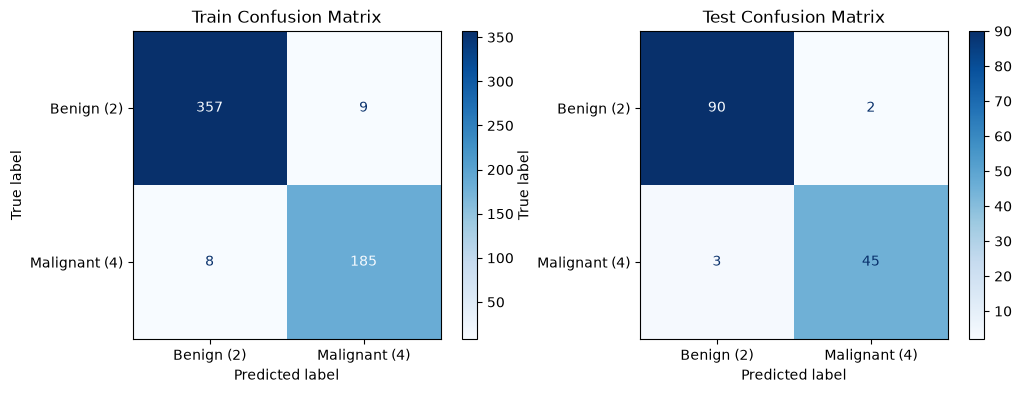

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(cm_train, display_labels=["Benign (2)", "Malignant (4)"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title("Train Confusion Matrix")

ConfusionMatrixDisplay(cm_test, display_labels=["Benign (2)", "Malignant (4)"]).plot(ax=axes[1], cmap="Blues")
axes[1].set_title("Test Confusion Matrix")
plt.show()
